# Airfoil Self-Noise Prediction

A NASA wind-tunnel dataset: 1,503 airfoil runs varying frequency, angle of attack, chord length, air velocity and suction-side thickness. The task is to predict the **scaled sound pressure level (dB)** the airfoil produces — a real aeroacoustics problem, because quieter blades and wings start with exactly this kind of model.


In [1]:
import io, urllib.request, zipfile
import numpy as np
import pandas as pd

def download(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=120) as r:
        return r.read()
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error

raw = download('https://archive.ics.uci.edu/static/public/291/airfoil+self+noise.zip')
zf = zipfile.ZipFile(io.BytesIO(raw))
name = [n for n in zf.namelist() if n.endswith('.dat')][0]
cols = ['frequency', 'angle_of_attack', 'chord_length', 'free_stream_velocity', 'suction_side_thickness', 'scaled_sound_pressure']
df = pd.read_csv(io.BytesIO(zf.read(name)), sep=r'\s+', header=None, names=cols)
print(df.shape)
df.head()

(1503, 6)


,frequency,angle_of_attack,chord_length,free_stream_velocity,suction_side_thickness,scaled_sound_pressure
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


In [2]:
X = df.drop(columns=['scaled_sound_pressure']); y = df['scaled_sound_pressure']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42)
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
lin = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr, ytr)
for name_m, m in [('Random Forest', rf), ('Linear', lin)]:
    p = m.predict(Xte)
    print(f'{name_m:15s} R2 {r2_score(yte, p):.3f}  MAE {mean_absolute_error(yte, p):.2f} dB')

Random Forest   R2 0.932  MAE 1.32 dB
Linear          R2 0.518  MAE 3.69 dB


frequency                 0.417762
suction_side_thickness    0.403130
chord_length              0.093745
angle_of_attack           0.044226
free_stream_velocity      0.041138
dtype: float64


<Axes: title={'center': 'What drives airfoil noise?'}>

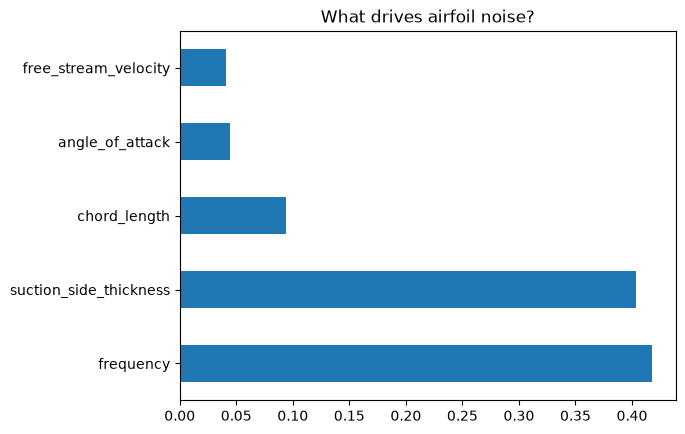

In [3]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp)
imp.plot(kind='barh', title='What drives airfoil noise?')